# 04 - Evaluation and Error Analysis
### ActivitySense AI | Yash Rajput - 2427010652

Detailed evaluation of the best model: per-class recall, confusion matrix, which activities get
confused (RQ4), and feature importance.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.data_loader import load_test
from src.predict import load_model, load_metadata
from src.evaluate import per_class_recall, confusion, report
from src import config as C, visualize as V

Xte, yte, yte_name, _ = load_test()
meta = load_metadata()
labels = meta["labels"]
best = load_model(meta["best_model"])
y_pred = best.predict(Xte[meta["feature_cols_full"]])
print("Best model:", meta["best_model"], "| test accuracy:", round(meta["test_accuracy"], 3))

Best model: svm | test accuracy: 0.954


## Per-class recall and classification report

In [3]:
for a, r in per_class_recall(yte_name, y_pred, labels).items():
    print(f"  {a:20s} recall={r}")
print("\n", report(yte_name, y_pred))

  WALKING              recall=0.974
  WALKING_UPSTAIRS     recall=0.964
  WALKING_DOWNSTAIRS   recall=0.917
  SITTING              recall=0.892
  STANDING             recall=0.968
  LAYING               recall=1.0

                     precision    recall  f1-score   support

            LAYING       0.99      1.00      1.00       537
           SITTING       0.96      0.89      0.93       491
          STANDING       0.91      0.97      0.94       532
           WALKING       0.95      0.97      0.96       496
WALKING_DOWNSTAIRS       0.97      0.92      0.94       420
  WALKING_UPSTAIRS       0.93      0.96      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



## Confusion matrix (RQ4)

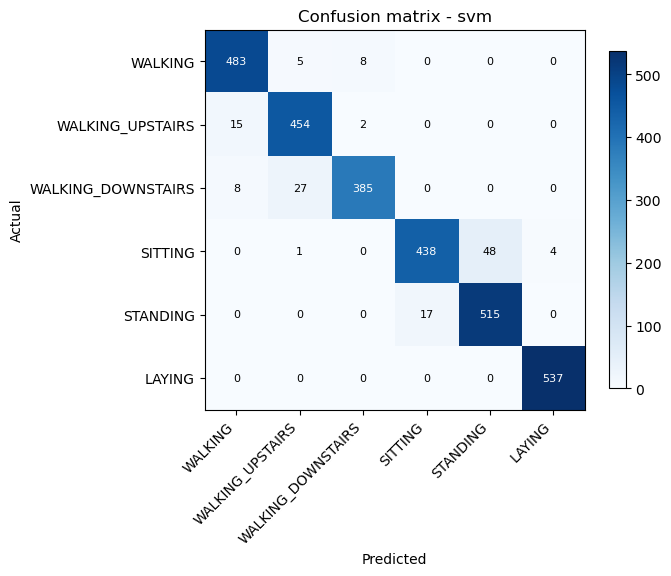

In [4]:
cm = confusion(yte_name, y_pred, labels)
V.plot_confusion(cm, labels, C.FIGURES_DIR / "confusion_matrix.png",
                 title=f"Confusion matrix - {meta['best_model']}")
plt.show()

In [5]:
import numpy as np
cmo = cm.copy(); np.fill_diagonal(cmo, 0)
i, j = np.unravel_index(cmo.argmax(), cmo.shape)
print(f"Most confused pair: {labels[i]} -> {labels[j]} ({cmo[i, j]} samples)")

Most confused pair: SITTING -> STANDING (48 samples)


As expected, the errors concentrate among the **static** activities (sitting vs standing) and
occasionally between the stair-climbing activities - these produce the most similar sensor
patterns. The dynamic/static boundary is almost never crossed.

## Feature importance (Random Forest)

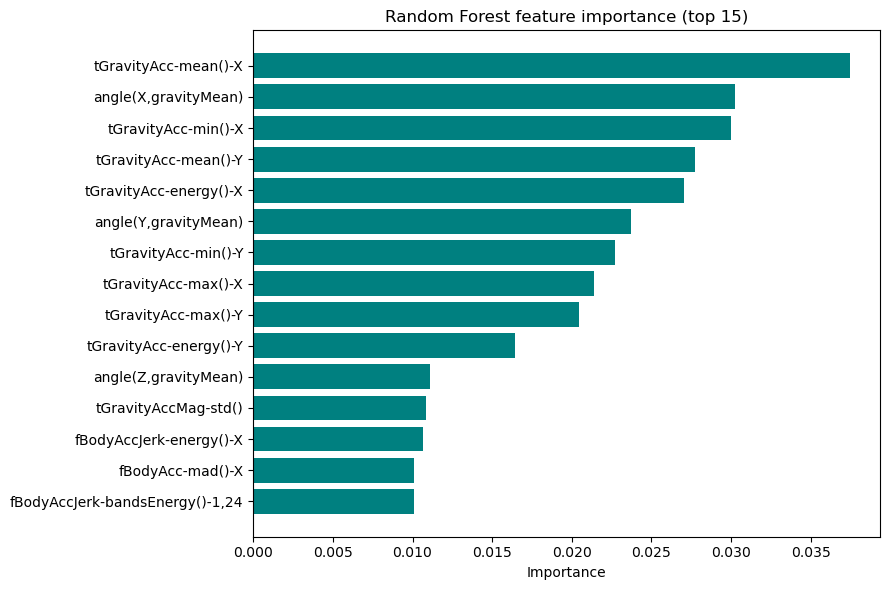

In [6]:
rf = load_model("random_forest")
imp = pd.Series(rf.feature_importances_, index=meta["feature_cols_full"])
V.plot_feature_importance(imp, C.FIGURES_DIR / "feature_importance.png")
plt.show()

## Conclusion
- **RQ1:** SVM achieved the best accuracy (~0.95); Random Forest was close and predicted fastest,
  while KNN was the weakest and slowest at inference.
- **RQ2:** accelerometer features alone clearly outperform gyroscope features alone.
- **RQ3:** a reduced 50-feature subset retained most of the full-feature accuracy.
- **RQ4:** the remaining errors are mainly sitting-vs-standing confusions.
- The UCI HAR features are already heavily engineered, which is why even simple models do well.